# FAUST articulation runtime versus input vertex count

Analyze the overnight articulation experiments launched by `batch-cuda-0.sh` and `batch-cuda-1.sh`. The experiment follows the Raw FAUST articulation setup in `STEPS.md`: approximately decimated 5k, 10k, 20k, 40k, 80k, and 120k scans plus the original full-resolution scans.

The notebook reads the append-only JSONL logs, keeps the latest successful record for each input path, measures the actual input mesh vertex count, and discovers runtime stage names directly from the logs.

In [13]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd
import scienceplots
import seaborn as sns
import trimesh
from IPython.display import display


def find_repository_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "articulate").is_dir():
            return candidate
    raise RuntimeError(f"Could not locate the ATM repository from {start}")


REPOSITORY_ROOT = find_repository_root(Path.cwd())
if str(REPOSITORY_ROOT) not in sys.path:
    sys.path.insert(0, str(REPOSITORY_ROOT))

from articulate.runtime_logging import read_runtime_records, select_runtime_records

# Match notebook/inference_time_plots.ipynb while remaining runnable without LaTeX.
plt.style.use(["science", "no-latex"])
plt.rcParams["font.size"] = 16
REPOSITORY_ROOT

PosixPath('/home/knpob/work/code/atm-dev')

## Experiment layout

`_09` scans were launched by `batch-cuda-0.sh`; `_08` scans were launched by `batch-cuda-1.sh` with `device=cuda:1`. Keeping this cohort label visible helps distinguish a vertex-count trend from a systematic difference between the two GPUs.

In [14]:
RESOLUTION_ORDER = ["5k", "10k", "20k", "40k", "80k", "120k", "raw"]
EXPERIMENTS = {
    resolution: REPOSITORY_ROOT / "output" / f"faust_{resolution}" / "articulation_runtime.jsonl"
    for resolution in RESOLUTION_ORDER
}

missing_logs = [path for path in EXPERIMENTS.values() if not path.is_file()]
if missing_logs:
    formatted = "\n".join(f"- {path}" for path in missing_logs)
    raise FileNotFoundError(f"Missing runtime logs:\n{formatted}")

EXPERIMENTS

{'5k': PosixPath('/home/knpob/work/code/atm-dev/output/faust_5k/articulation_runtime.jsonl'),
 '10k': PosixPath('/home/knpob/work/code/atm-dev/output/faust_10k/articulation_runtime.jsonl'),
 '20k': PosixPath('/home/knpob/work/code/atm-dev/output/faust_20k/articulation_runtime.jsonl'),
 '40k': PosixPath('/home/knpob/work/code/atm-dev/output/faust_40k/articulation_runtime.jsonl'),
 '80k': PosixPath('/home/knpob/work/code/atm-dev/output/faust_80k/articulation_runtime.jsonl'),
 '120k': PosixPath('/home/knpob/work/code/atm-dev/output/faust_120k/articulation_runtime.jsonl'),
 'raw': PosixPath('/home/knpob/work/code/atm-dev/output/faust_raw/articulation_runtime.jsonl')}

In [15]:
def gpu_cohort(shape_name: str) -> str:
    if shape_name.startswith("tr_scan_08"):
        return "CUDA 1 (_08)"
    if shape_name.startswith("tr_scan_09"):
        return "CUDA 0 (_09)"
    return "Unassigned"


def mesh_vertex_count(path: str) -> int:
    mesh = trimesh.load(path, process=False, force="mesh")
    if not isinstance(mesh, trimesh.Trimesh):
        raise TypeError(f"Expected one mesh at {path}, got {type(mesh).__name__}")
    return int(len(mesh.vertices))


record_rows = []
stage_rows = []
stage_order = []

for resolution, log_path in EXPERIMENTS.items():
    records = select_runtime_records(read_runtime_records(log_path))
    for record_index, record in enumerate(records):
        shape_name = record["shape"]["name"]
        base = {
            "resolution": resolution,
            "shape_name": shape_name,
            "shape_path": record["shape"]["path"],
            "vertex_count": mesh_vertex_count(record["shape"]["path"]),
            "gpu_cohort": gpu_cohort(shape_name),
            "run_id": record["run_id"],
            "pipeline": record["pipeline"],
            "finished_at_utc": record["finished_at_utc"],
            "lifecycle_seconds": record["lifecycle_seconds"],
            "articulation_seconds": record["articulation_seconds"],
        }
        record_rows.append(base)
        for stage_index, stage in enumerate(record["stages"]):
            if stage["name"] not in stage_order:
                stage_order.append(stage["name"])
            stage_rows.append(
                {
                    **base,
                    "stage_index": stage_index,
                    "stage": stage["name"],
                    "seconds": stage["seconds"],
                }
            )

record_frame = pd.DataFrame(record_rows)
stage_frame = pd.DataFrame(stage_rows)
record_frame["resolution"] = pd.Categorical(
    record_frame["resolution"], categories=RESOLUTION_ORDER, ordered=True
)
stage_frame["resolution"] = pd.Categorical(
    stage_frame["resolution"], categories=RESOLUTION_ORDER, ordered=True
)
stage_frame["stage"] = pd.Categorical(
    stage_frame["stage"], categories=stage_order, ordered=True
)

assert set(record_frame["resolution"].dropna()) == set(RESOLUTION_ORDER)
assert (record_frame.groupby("resolution", observed=True).size() > 0).all()
print(f"Loaded {len(record_frame)} latest successful shape records")

Loaded 140 latest successful shape records


## Coverage and measured mesh sizes

The decimator treats each requested size as an approximate target. Plots therefore use measured vertex counts rather than assuming the directory label is exact.

In [16]:
coverage = (
    record_frame.groupby("resolution", observed=True, sort=False)
    .agg(
        shapes=("shape_path", "count"),
        runs=("run_id", "nunique"),
        vertices_min=("vertex_count", "min"),
        vertices_mean=("vertex_count", "mean"),
        vertices_max=("vertex_count", "max"),
    )
    .reset_index()
)
coverage["vertices_mean"] = coverage["vertices_mean"].round(1)
display(coverage)

,resolution,shapes,runs,vertices_min,vertices_mean,vertices_max
0,5k,20,2,5000,5019.6,5042
1,10k,20,2,10000,10027.2,10067
2,20k,20,2,19999,20033.1,20080
3,40k,20,2,40001,40046.0,40114
4,80k,20,2,79995,80056.4,80137
5,120k,20,2,119992,120063.0,120144
6,raw,20,2,165952,182722.6,207133


## Runtime summary

`lifecycle_seconds` includes input loading, view rendering, articulation, and output export. `articulation_seconds` is the sum of all stages recorded by that pipeline.

In [17]:
def percentile_95(values):
    return values.quantile(0.95)


runtime_summary = (
    record_frame.groupby("resolution", observed=True, sort=False)
    .agg(
        shapes=("shape_path", "count"),
        vertex_count_mean=("vertex_count", "mean"),
        lifecycle_mean=("lifecycle_seconds", "mean"),
        lifecycle_std=("lifecycle_seconds", "std"),
        lifecycle_median=("lifecycle_seconds", "median"),
        lifecycle_p95=("lifecycle_seconds", percentile_95),
        articulation_mean=("articulation_seconds", "mean"),
        articulation_std=("articulation_seconds", "std"),
        articulation_median=("articulation_seconds", "median"),
        articulation_p95=("articulation_seconds", percentile_95),
    )
    .reset_index()
)
numeric_columns = runtime_summary.select_dtypes(include="number").columns
runtime_summary[numeric_columns] = runtime_summary[numeric_columns].round(2)
display(runtime_summary)

,resolution,shapes,vertex_count_mean,lifecycle_mean,lifecycle_std,lifecycle_median,lifecycle_p95,articulation_mean,articulation_std,articulation_median,articulation_p95
0,5k,20,5019.55,67.51,2.06,67.08,70.75,64.90,2.04,64.59,68.07
1,10k,20,10027.15,67.73,1.99,67.52,70.15,64.95,1.91,64.56,67.58
2,20k,20,20033.10,68.06,2.85,68.84,71.44,65.32,2.99,66.28,68.74
3,40k,20,40046.00,69.58,2.57,69.19,73.06,66.67,2.51,66.33,69.55
4,80k,20,80056.40,71.42,2.60,71.64,75.56,68.42,2.65,68.74,72.54
5,120k,20,120063.05,72.31,1.99,72.74,75.18,69.00,1.87,69.57,71.27
6,raw,20,182722.55,72.54,2.86,71.77,76.62,69.14,3.00,68.48,73.26


## Total runtime trend

Faint points are individual shapes. Lines show the mean at each resolution with a 95% confidence interval. A logarithmic vertex-count axis keeps all seven resolutions legible; raw scans retain their actual 166k–207k spread.

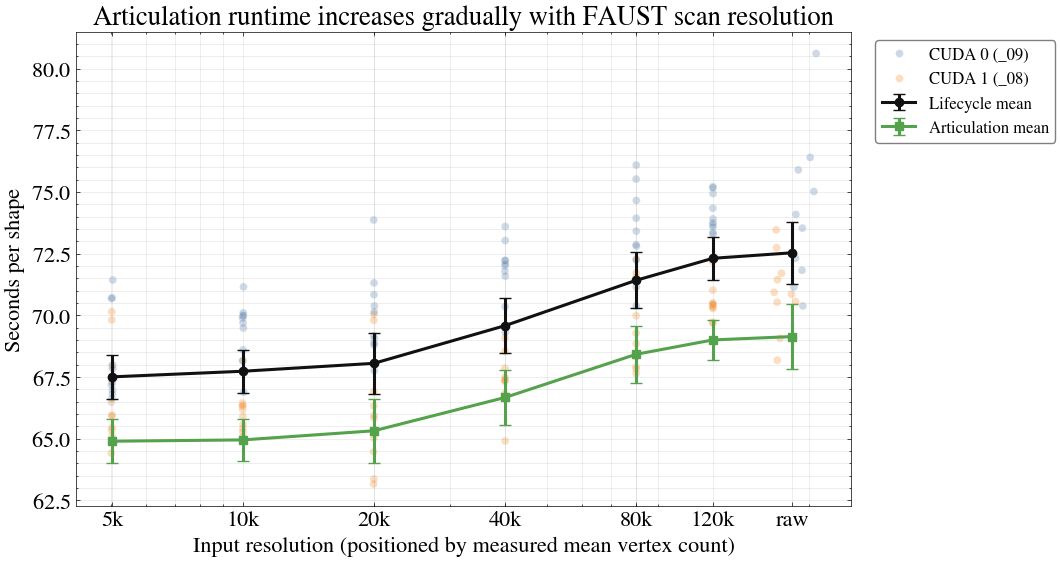

In [18]:
def confidence_interval_95(values):
    values = np.asarray(values, dtype=float)
    standard_error = values.std(ddof=1) / np.sqrt(len(values))
    return 1.96 * standard_error


resolution_x = (
    record_frame.groupby("resolution", observed=True, sort=False)["vertex_count"]
    .mean()
    .reindex(RESOLUTION_ORDER)
)

figure, axis = plt.subplots(figsize=(11, 6))
cohort_palette = {"CUDA 0 (_09)": "#4C78A8", "CUDA 1 (_08)": "#F58518"}
sns.scatterplot(
    data=record_frame,
    x="vertex_count",
    y="lifecycle_seconds",
    hue="gpu_cohort",
    palette=cohort_palette,
    alpha=0.28,
    s=32,
    ax=axis,
)

for metric, label, color, marker in [
    ("lifecycle_seconds", "Lifecycle mean", "#111111", "o"),
    ("articulation_seconds", "Articulation mean", "#54A24B", "s"),
]:
    grouped = record_frame.groupby("resolution", observed=True, sort=False)[metric]
    means = grouped.mean().reindex(RESOLUTION_ORDER)
    intervals = grouped.apply(confidence_interval_95).reindex(RESOLUTION_ORDER)
    axis.errorbar(
        resolution_x.values,
        means.values,
        yerr=intervals.values,
        color=color,
        marker=marker,
        linewidth=2.2,
        capsize=4,
        label=label,
    )

axis.set_xscale("log")
axis.set_xticks(resolution_x.values)
axis.set_xticklabels(RESOLUTION_ORDER)
axis.set_xlabel("Input resolution (positioned by measured mean vertex count)")
axis.set_ylabel("Seconds per shape")
axis.set_title("Articulation runtime increases gradually with FAUST scan resolution")
axis.legend(
    title=None,
    frameon=True,
    edgecolor="black",
    framealpha=0.5,
    fontsize=12,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)
axis.grid(True, which="both", alpha=0.3, linestyle="-", linewidth=0.5)
plt.tight_layout()
plt.show()

## GPU-cohort trend

This view preserves the launch split from the two batch scripts. It is useful for checking whether a pooled trend is driven by one device or scan cohort.

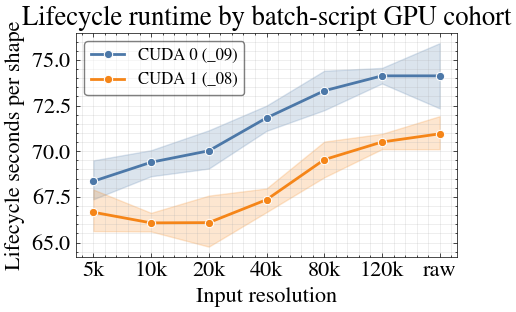

In [19]:
figure, axis = plt.subplots(figsize=(5, 3.5))
sns.lineplot(
    data=record_frame,
    x="resolution",
    y="lifecycle_seconds",
    hue="gpu_cohort",
    hue_order=["CUDA 0 (_09)", "CUDA 1 (_08)"],
    palette=cohort_palette,
    estimator="mean",
    errorbar=("ci", 95),
    marker="o",
    linewidth=2,
    ax=axis,
)
axis.set_xlabel("Input resolution")
axis.set_ylabel("Lifecycle seconds per shape")
axis.set_title("Lifecycle runtime by batch-script GPU cohort")
axis.legend(
    title=None,
    frameon=True,
    edgecolor="black",
    framealpha=0.5,
    fontsize=12,
    loc="best",
)
axis.grid(True, which="both", alpha=0.3, linestyle="-", linewidth=0.5)
plt.tight_layout()
plt.show()

## Stage-wise trend

Stage names and ordering are read from the log. A future pipeline can add, remove, or rename stages without changing this plotting cell.

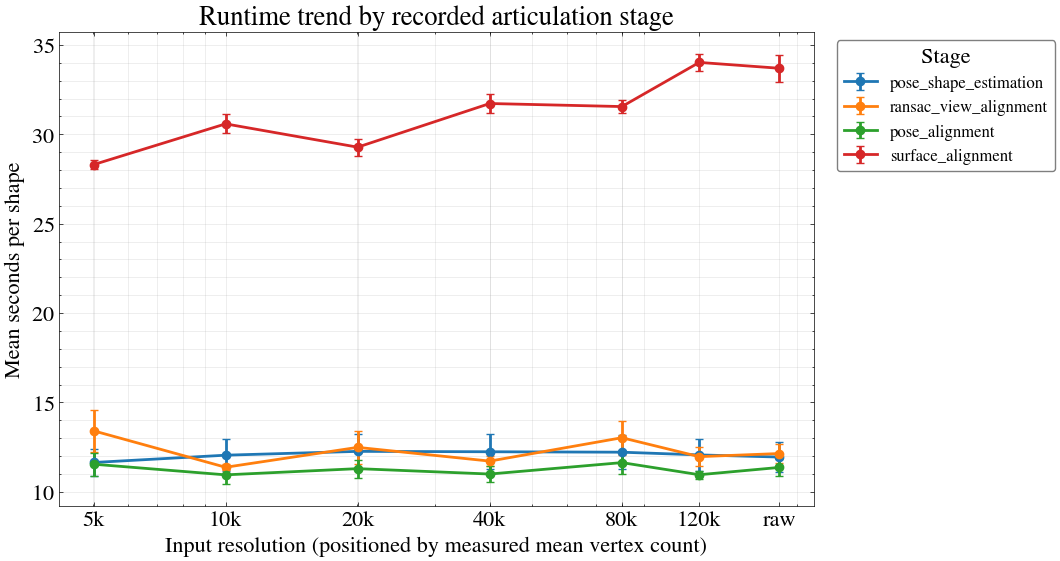

,resolution,stage,seconds_mean,seconds_std,samples,seconds_ci95
0,5k,pose_shape_estimation,11.639,1.752,20,0.768
1,5k,ransac_view_alignment,13.411,2.719,20,1.192
2,5k,pose_alignment,11.544,1.446,20,0.634
3,5k,surface_alignment,28.303,0.552,20,0.242
4,10k,pose_shape_estimation,12.048,2.017,20,0.884
5,10k,ransac_view_alignment,11.372,0.367,20,0.161
6,10k,pose_alignment,10.947,1.169,20,0.512
7,10k,surface_alignment,30.583,1.227,20,0.538
8,20k,pose_shape_estimation,12.261,2.234,20,0.979
9,20k,ransac_view_alignment,12.485,2.072,20,0.908


In [20]:
stage_summary = (
    stage_frame.groupby(["resolution", "stage"], observed=True, sort=False)
    .agg(
        seconds_mean=("seconds", "mean"),
        seconds_std=("seconds", "std"),
        samples=("seconds", "count"),
    )
    .reset_index()
)
stage_summary["seconds_ci95"] = (
    1.96 * stage_summary["seconds_std"] / np.sqrt(stage_summary["samples"])
)

figure, axis = plt.subplots(figsize=(11, 6))
stage_palette = sns.color_palette("tab10", n_colors=len(stage_order))
for stage, color in zip(stage_order, stage_palette):
    values = (
        stage_summary[stage_summary["stage"].astype(str) == stage]
        .set_index("resolution")
        .reindex(RESOLUTION_ORDER)
    )
    axis.errorbar(
        resolution_x.values,
        values["seconds_mean"].values,
        yerr=values["seconds_ci95"].values,
        marker="o",
        linewidth=2,
        capsize=3,
        color=color,
        label=stage,
    )

axis.set_xscale("log")
axis.set_xticks(resolution_x.values)
axis.set_xticklabels(RESOLUTION_ORDER)
axis.set_xlabel("Input resolution (positioned by measured mean vertex count)")
axis.set_ylabel("Mean seconds per shape")
axis.set_title("Runtime trend by recorded articulation stage")
axis.legend(
    title="Stage",
    frameon=True,
    edgecolor="black",
    framealpha=0.5,
    fontsize=12,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)
axis.grid(True, which="both", alpha=0.3, linestyle="-", linewidth=0.5)
plt.tight_layout()
plt.show()

display(stage_summary.round(3))

## Mean stage composition

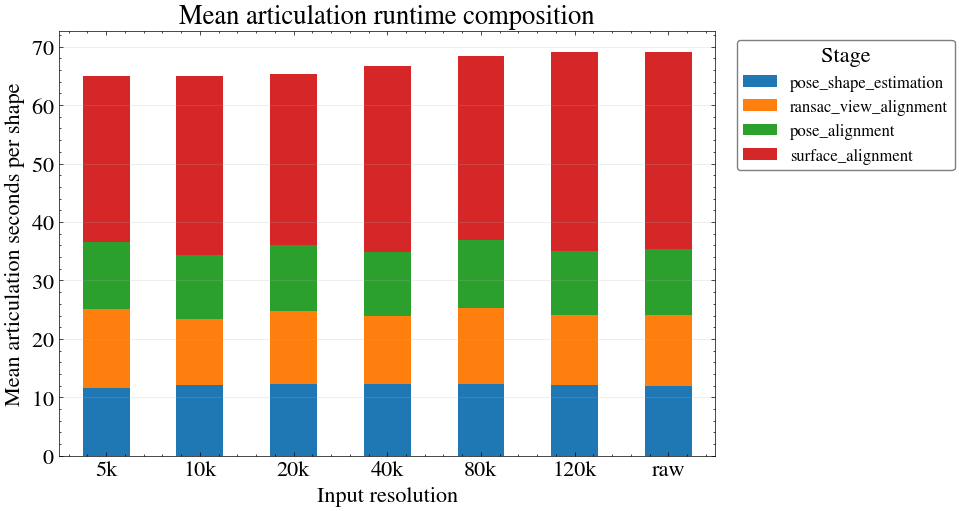

In [21]:
stage_composition = (
    stage_frame.groupby(["resolution", "stage"], observed=True, sort=False)["seconds"]
    .mean()
    .unstack("stage")
    .reindex(index=RESOLUTION_ORDER, columns=stage_order)
)

axis = stage_composition.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5.5),
    color=stage_palette,
)
axis.set_xlabel("Input resolution")
axis.set_ylabel("Mean articulation seconds per shape")
axis.set_title("Mean articulation runtime composition")
axis.legend(
    title="Stage",
    frameon=True,
    edgecolor="black",
    framealpha=0.5,
    fontsize=12,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)
axis.grid(True, axis="y", alpha=0.3, linestyle="-", linewidth=0.5)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Benchmark comparisons

`notebook/benchmark_results.csv` combines the latest ATM articulation runtimes with the reported ATM, URSSM, and ZoomOut matching results. CSV rows use nominal vertex counts so they remain aligned with the resolution labels in the paper table.

In [22]:
BENCHMARK_RESULTS_PATH = REPOSITORY_ROOT / "notebook" / "benchmark_results.csv"
if not BENCHMARK_RESULTS_PATH.is_file():
    raise FileNotFoundError(f"Missing benchmark CSV: {BENCHMARK_RESULTS_PATH}")

benchmark_frame = pd.read_csv(BENCHMARK_RESULTS_PATH)
required_benchmark_columns = {
    "method_group",
    "variant",
    "vertices",
    "time_minutes",
    "error",
    "iterations_per_sec",
    "status",
}
missing_benchmark_columns = required_benchmark_columns.difference(benchmark_frame.columns)
if missing_benchmark_columns:
    formatted = ", ".join(sorted(missing_benchmark_columns))
    raise ValueError(f"Benchmark CSV is missing columns: {formatted}")

atm_benchmark = benchmark_frame[
    (benchmark_frame["method_group"] == "our_method")
    & (benchmark_frame["variant"] == "spectral-icp")
    & (benchmark_frame["status"] == "success")
].sort_values("vertices")
if atm_benchmark.empty:
    raise RuntimeError("No successful ATM spectral-icp rows were found")

atm_benchmark = atm_benchmark.assign(
    articulation_seconds_per_shape=atm_benchmark["time_minutes"] / 20 * 60,
    matching_seconds_per_pair=1 / atm_benchmark["iterations_per_sec"],
)
display(
    atm_benchmark[
        [
            "resolution",
            "vertices",
            "articulation_seconds_per_shape",
            "matching_seconds_per_pair",
            "error",
        ]
    ]
)

,resolution,vertices,articulation_seconds_per_shape,matching_seconds_per_pair,error
20,5k,5000,64.897014,0.502513,2.4
17,10k,10000,64.949871,0.520833,2.2
14,20k,20000,65.319960,0.609756,2.2
11,40k,40000,66.670710,0.757576,2.2
8,80k,80000,68.422434,1.449275,2.2
5,120k,120000,69.004227,2.325581,2.2
2,full,200000,69.140406,4.761905,2.1


### Inference-time components

As in `inference_time_plots.ipynb`, the CSV's 20-shape articulation totals are converted from minutes to seconds per shape, while map extraction and refinement time is the reciprocal of measured pairs per second.

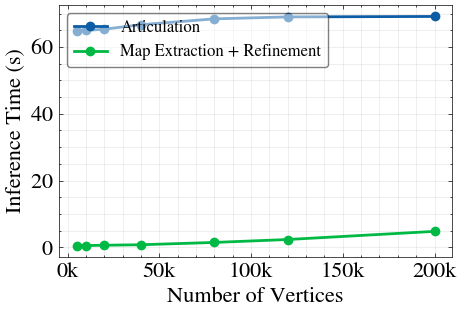

In [23]:
figure, axis = plt.subplots(figsize=(5, 3.5))
axis.plot(
    atm_benchmark["vertices"],
    atm_benchmark["articulation_seconds_per_shape"],
    marker="o",
    linewidth=2,
    label="Articulation",
)
axis.plot(
    atm_benchmark["vertices"],
    atm_benchmark["matching_seconds_per_pair"],
    marker="o",
    linewidth=2,
    label="Map Extraction + Refinement",
)

axis.xaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value / 1000:g}k")
)
axis.set_xlabel("Number of Vertices")
axis.set_ylabel("Inference Time (s)")
axis.legend(
    frameon=True,
    edgecolor="black",
    framealpha=0.5,
    fontsize=12,
    loc="upper left",
)
axis.grid(True, which="both", alpha=0.3, linestyle="-", linewidth=0.5)
plt.tight_layout()
plt.show()

### Geodesic error and baseline scalability

ZoomOut now succeeds through the raw-resolution benchmark. The vertical dotted line marks 40k, the first resolution at which both URSSM initializations are reported as out of memory.

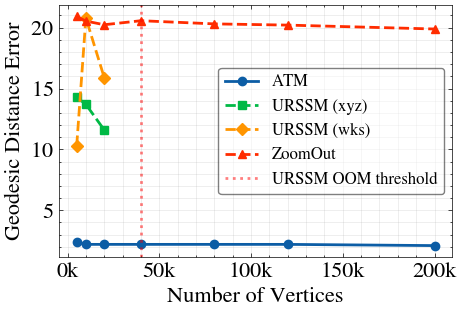

In [24]:
successful_benchmarks = benchmark_frame[benchmark_frame["status"] == "success"]
ulrssm_xyz_data = successful_benchmarks[
    (successful_benchmarks["method_group"] == "ulrssm")
    & (successful_benchmarks["variant"] == "xyz")
].sort_values("vertices")
ulrssm_wks_data = successful_benchmarks[
    (successful_benchmarks["method_group"] == "ulrssm")
    & (successful_benchmarks["variant"] == "wks")
].sort_values("vertices")
zoomout_data = successful_benchmarks[
    (successful_benchmarks["method_group"] == "zoomout")
    & (successful_benchmarks["variant"] == "spatial-init")
].sort_values("vertices")
if ulrssm_xyz_data.empty or ulrssm_wks_data.empty or zoomout_data.empty:
    raise RuntimeError("The CSV must contain successful URSSM and ZoomOut rows")

figure, axis = plt.subplots(figsize=(5, 3.5))
axis.plot(
    atm_benchmark["vertices"],
    atm_benchmark["error"],
    marker="o",
    linewidth=2,
    label="ATM",
)
axis.plot(
    ulrssm_xyz_data["vertices"],
    ulrssm_xyz_data["error"],
    marker="s",
    linewidth=2,
    linestyle="--",
    label="URSSM (xyz)",
)
axis.plot(
    ulrssm_wks_data["vertices"],
    ulrssm_wks_data["error"],
    marker="D",
    linewidth=2,
    linestyle="--",
    label="URSSM (wks)",
)
axis.plot(
    zoomout_data["vertices"],
    zoomout_data["error"],
    marker="^",
    linewidth=2,
    linestyle="--",
    label="ZoomOut",
)

ulrssm_oom = benchmark_frame[
    (benchmark_frame["method_group"] == "ulrssm")
    & (benchmark_frame["status"] == "oom")
]
if not ulrssm_oom.empty:
    axis.axvline(
        ulrssm_oom["vertices"].min(),
        color="red",
        linestyle=":",
        alpha=0.5,
        linewidth=2,
        label="URSSM OOM threshold",
    )

axis.xaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value / 1000:g}k")
)
axis.set_xlabel("Number of Vertices")
axis.set_ylabel("Geodesic Distance Error")
axis.legend(
    frameon=True,
    edgecolor="black",
    framealpha=0.5,
    fontsize=12,
    loc="best",
)
axis.grid(True, which="both", alpha=0.3, linestyle="-", linewidth=0.5)
plt.tight_layout()
plt.show()

## Interpretation checklist

- Each resolution should contain 20 latest successful shapes: ten `_08` and ten `_09` scans across two run IDs.
- Use the cohort plot before attributing a small difference solely to vertex count; the two scan families ran on different CUDA devices.
- Surface optimization samples a configured number of target points, so its cost need not scale linearly with every input vertex.
- Raw scans vary substantially in size; their individual points are more informative than treating `raw` as one exact vertex count.
- The JSONL logs contain successful attempts only, so failed retries are not part of these runtime distributions.